# Music genre classification

Compare an RBF SVM and random forest using FMA-small's provided splits.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

root = Path.cwd() if Path("requirements.txt").is_file() else Path.cwd().parent
data = root / "data" / "fma_metadata"
results = root / "results"
results.mkdir(exist_ok=True)


## Load FMA-small

Keep the supplied split assignments and align labels with audio features by track ID.

In [2]:
tracks = pd.read_csv(data / "tracks.csv", index_col=0, header=[0, 1], low_memory=False)
features = pd.read_csv(data / "features.csv", index_col=0, header=[0, 1, 2])
if not tracks.index.is_unique or not features.index.is_unique:
    raise ValueError("Expected unique track IDs in both source tables.")

small = tracks.loc[tracks[("set", "subset")].eq("small")]
labels = small[("track", "genre_top")]
split = small[("set", "split")]
X = features.reindex(small.index).replace([np.inf, -np.inf], np.nan)
feature_families = X.columns.get_level_values(0)
X.columns = [" / ".join(column) for column in X.columns]
usable = labels.notna() & X.notna().any(axis=1)
print(f"Using {usable.sum()} of {len(small)} tracks.")
X, labels, split = X.loc[usable], labels.loc[usable], split.loc[usable]
assert set(split.unique()) == {"training", "validation", "test"}
genres = sorted(labels.unique())
assert len(genres) == 8
display(pd.crosstab(labels, split))

artists_by_split = {
    name: set(small.loc[split.index[split.eq(name)], ("artist", "id")].dropna())
    for name in ("training", "validation", "test")
}
assert not (artists_by_split["training"] & artists_by_split["validation"])
assert not (artists_by_split["training"] & artists_by_split["test"])
assert not (artists_by_split["validation"] & artists_by_split["test"])
print("Verified no artist overlap across splits.")
print(f"{X.shape[1]} audio features across {feature_families.nunique()} families.")


Using 8000 of 8000 tracks.


"(set, split)",test,training,validation
"(track, genre_top)",,,
Electronic,100,800,100
Experimental,100,800,100
Folk,100,800,100
Hip-Hop,100,800,100
Instrumental,100,800,100
International,100,800,100
Pop,100,800,100
Rock,100,800,100


Verified no artist overlap across splits.
518 audio features across 11 families.


## Tune on validation data

Imputation and scaling are fitted inside each training pipeline. The search keeps the test split out and refits the chosen models on training plus validation before final scoring.

In [3]:
development = split.ne("test")
validation = split.eq("validation")
test = split.eq("test")
training = split.eq("training")
cv = PredefinedSplit(np.where(validation.loc[development], 0, -1))

models = {
    "svm": (
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVC(kernel="rbf")),
        {"svc__C": [1, 10], "svc__gamma": ["scale", 0.001]},
    ),
    "forest": (
        make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(random_state=42)),
        {"randomforestclassifier__max_depth": [20, None],
         "randomforestclassifier__n_estimators": [150, 300]},
    ),
}

searches = {}
for name, (pipeline, parameters) in models.items():
    search = GridSearchCV(pipeline, parameters, cv=cv, scoring="f1_macro", n_jobs=2,
                          error_score="raise")
    search.fit(X.loc[development], labels.loc[development])
    searches[name] = search
    print(name, search.best_params_, round(search.best_score_, 4))


svm {'svc__C': 1, 'svc__gamma': 0.001} 0.5464


forest {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 300} 0.5383


## Evaluate on the held-out test set

Each confusion matrix row shows the fraction of tracks in that true genre assigned to each predicted genre.

A majority-class baseline gives the two models a simple benchmark. On this balanced test set, it gets one of the eight genres right.

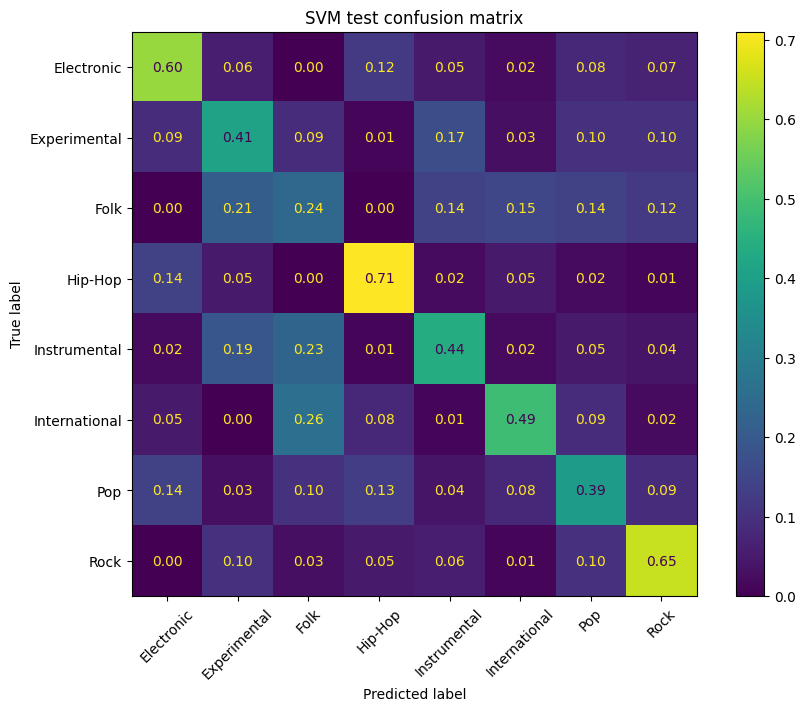

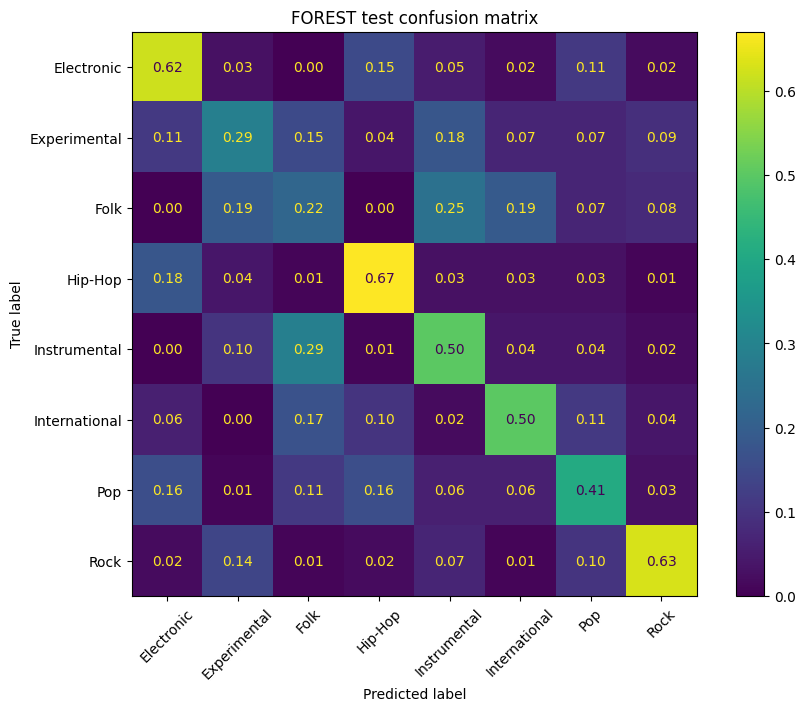

,validation_macro_f1,test_accuracy,test_macro_f1
model,,,
majority_baseline,0.027778,0.12500,0.027778
svm,0.546410,0.49125,0.488506
forest,0.538348,0.48000,0.476180


In [4]:
truth = labels.loc[test]
baseline = DummyClassifier(strategy="most_frequent").fit(X.loc[development], labels.loc[development])
baseline_prediction = baseline.predict(X.loc[test])
scores = [{
    "model": "majority_baseline",
    "validation_macro_f1": f1_score(
        labels.loc[validation],
        DummyClassifier(strategy="most_frequent").fit(
            X.loc[training], labels.loc[training]
        ).predict(X.loc[validation]),
        average="macro",
    ),
    "test_accuracy": accuracy_score(truth, baseline_prediction),
    "test_macro_f1": f1_score(truth, baseline_prediction, average="macro"),
}]
for name, search in searches.items():
    prediction = search.predict(X.loc[test])
    scores.append({"model": name, "validation_macro_f1": search.best_score_,
                   "test_accuracy": accuracy_score(truth, prediction),
                   "test_macro_f1": f1_score(truth, prediction, average="macro")})

    report = classification_report(truth, prediction, labels=genres,
                                   output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(results / f"{name}_classification_report.csv")

    fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
    ConfusionMatrixDisplay.from_predictions(
        truth, prediction, labels=genres, normalize="true",
        xticks_rotation=45, values_format=".2f", ax=ax,
    )
    ax.set_title(f"{name.upper()} test confusion matrix")
    fig.savefig(results / f"{name}_confusion_matrix.png", dpi=180)
    plt.show()

metrics = pd.DataFrame(scores).set_index("model")
metrics.to_csv(results / "metrics.csv")
display(metrics)


## Which audio features matter?

Shuffle each family of related features together across validation tracks and measure the drop in macro F1. This keeps the relationships among summaries of the same audio feature intact. For each model, fit its selected configuration on training data only, then measure eight shuffles per family on validation data. The bars show the mean score drop, and the whiskers show variation across shuffles. A larger drop means the model depended more on that family in this experiment.

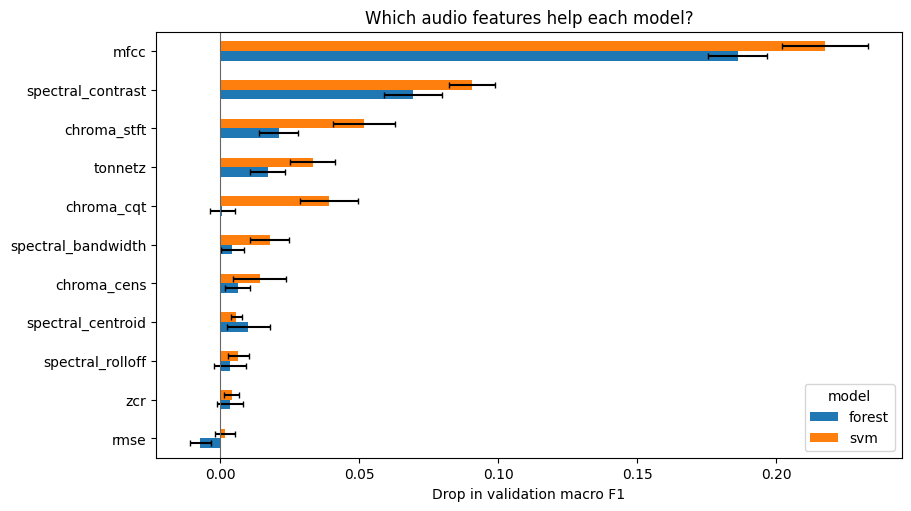

In [5]:
X_val, y_val = X.loc[validation], labels.loc[validation]
rng = np.random.default_rng(42)
permutations = [rng.permutation(len(X_val)) for _ in range(8)]
rows = []

for name, search in searches.items():
    model = clone(search.best_estimator_).fit(X.loc[training], labels.loc[training])
    original_score = f1_score(y_val, model.predict(X_val), average="macro")
    for family in feature_families.unique():
        columns = X.columns[feature_families == family]
        drops = []
        shuffled = X_val.copy()
        for order in permutations:
            shuffled[columns] = X_val[columns].to_numpy()[order]
            score = f1_score(y_val, model.predict(shuffled), average="macro")
            drops.append(original_score - score)
        rows.append({
            "model": name, "feature_family": family, "feature_count": len(columns),
            "macro_f1_drop": np.mean(drops), "shuffle_sd": np.std(drops, ddof=1),
        })

importance = pd.DataFrame(rows)
importance.to_csv(results / "feature_family_importance.csv", index=False)
means = importance.pivot(index="feature_family", columns="model", values="macro_f1_drop")
means = means.loc[means.mean(axis=1).sort_values().index]
errors = importance.pivot(index="feature_family", columns="model", values="shuffle_sd")
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
means.plot.barh(ax=ax, xerr=errors.reindex(means.index), capsize=2, rot=0)
ax.axvline(0, color="0.4", linewidth=0.8)
ax.set(xlabel="Drop in validation macro F1", ylabel="", title="Which audio features help each model?")
fig.savefig(results / "feature_family_importance.png", dpi=180)
plt.show()


## What the results show

Both models beat the 12.5% accuracy baseline. The SVM led the forest by about 1.1 percentage points on this test split. Both models recalled Hip-Hop most often (71% for SVM, 67% for forest) and Folk least often (24% and 22%). The SVM labeled 26 of 100 International tracks as Folk.

Shuffling MFCCs, which summarize aspects of a track's timbre, caused the largest drop in validation macro F1 for both models. Spectral contrast ranked second. Feature families vary in size and can overlap in what they capture, so compare these drops as measures of model reliance on groups of measurements. The whiskers show variability across shuffles on the same validation set.


## Demo: Would you accept the suggested tag?

Use three held-out tracks to try the cataloging workflow. Open each card to compare the model suggestions with the archive label. These examples were selected to illustrate three different outcomes and are separate from the aggregate performance estimates above.

For a listening demo, place the corresponding FMA-small MP3s under `data/fma_small/` in their original folders. The cards play those local clips when available.

In [6]:
from html import escape

from IPython.display import Audio, HTML, display

demo = pd.DataFrame({"archive": labels.loc[test]})
for name, search in searches.items():
    demo[name] = search.predict(X.loc[test])

cases = [
    ("Both models match the archive", demo.svm.eq(demo.archive) & demo.forest.eq(demo.archive)),
    ("The models disagree", demo.svm.ne(demo.forest) & demo.svm.eq(demo.archive)),
    ("Both models miss in the same way", demo.svm.eq(demo.forest) & demo.svm.ne(demo.archive)),
]
for number, (outcome, mask) in enumerate(cases, start=1):
    examples = demo.loc[mask].sort_index()
    if examples.empty:
        continue
    track_id = examples.index[0]
    row = examples.loc[track_id]
    title = escape(str(tracks.loc[track_id, ("track", "title")]))
    artist = escape(str(tracks.loc[track_id, ("artist", "name")]))
    track_key = f"{track_id:06d}"
    clip = data.parent / "fma_small" / track_key[:3] / f"{track_key}.mp3"
    display(HTML(f"<p><b>Track {number}</b> · {title} — {artist} (FMA {track_key})</p>"))
    if clip.is_file():
        display(Audio(filename=str(clip)))
    display(HTML(
        f"<details><summary>Reveal the predictions</summary>"
        f"<p>Archive label: <b>{escape(row.archive)}</b><br>"
        f"SVM: {escape(row.svm)}<br>Random forest: {escape(row.forest)}</p>"
        f"<p>{escape(outcome)}</p></details>"
    ))
